# Lab 4 Homework - K-Means vs. Agglomerative Clustering

# Part 1 - K-Means

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_iris
from sklearn.cluster import KMeans as SkKMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import pandas as pd
import time

plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e0dfdc',
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Setup complete')


Setup complete


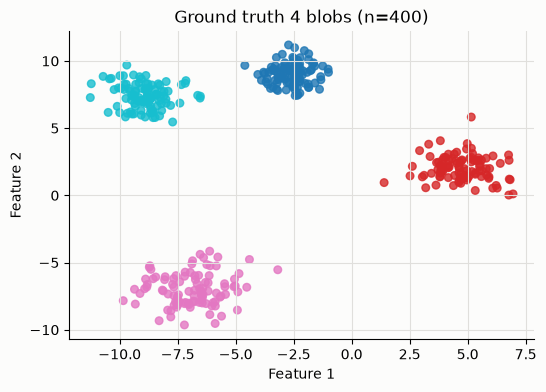

In [2]:
X, y_true = make_blobs(centers=4, n_samples=400, cluster_std=[0.8, 1.0, 1.2, 0.9], random_state=42)
n_clusters = len(np.unique(y_true))

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap='tab10', alpha=0.8, s=30)
plt.title(f'Ground truth {n_clusters} blobs (n={X.shape[0]})')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()


In [3]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

class KMeansImmediateUpdate:
    """K-Means with immediate centroid updates (online k-means)."""
    def __init__(self, K, max_iters=100, random_state=42):
        self.K = K
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None
        self.n_iters_used = 0

    def fit(self, X):
        self.X = X
        n = X.shape[0]
        rng = np.random.default_rng(self.random_state)

        # 1. Initialize with K random data points
        idx = rng.choice(n, self.K, replace=False)
        self.centroids = X[idx].copy()

        # Start with each point assigned to its nearest centroid
        D0 = np.stack([np.sum((X - c) ** 2, axis=1) for c in self.centroids], axis=1)
        membership = np.argmin(D0, axis=1)

        def update_centroid(j):
            members = X[membership == j]
            self.centroids[j] = (members.mean(axis=0)
                                 if len(members) > 0
                                 else X[rng.integers(n)])  # re-seed an empty cluster

        for it in range(1, self.max_iters + 1):
            any_change = False
            for i in range(n):
                # 2. Assign point i to the nearest cluster center
                new_c = int(np.argmin([euclidean(X[i], c) for c in self.centroids]))
                old_c = membership[i]
                if new_c != old_c:
                    membership[i] = new_c
                    any_change = True
                    # 3. IMMEDIATELY re-estimate the two affected cluster centers
                    update_centroid(old_c)
                    update_centroid(new_c)
            self.n_iters_used = it
            if not any_change:  # converged: no point changed membership this pass
                break

        return membership

    @property
    def inertia(self):
        D = np.stack([np.sum((self.X - c) ** 2, axis=1) for c in self.centroids], axis=1)
        m = np.argmin(D, axis=1)
        return float(D[np.arange(self.X.shape[0]), m].sum())

print('KMeansImmediateUpdate defined')


KMeansImmediateUpdate defined


Converged in 1 pass(es)
Inertia : 8824.34
ARI     : 0.583
NMI     : 0.717


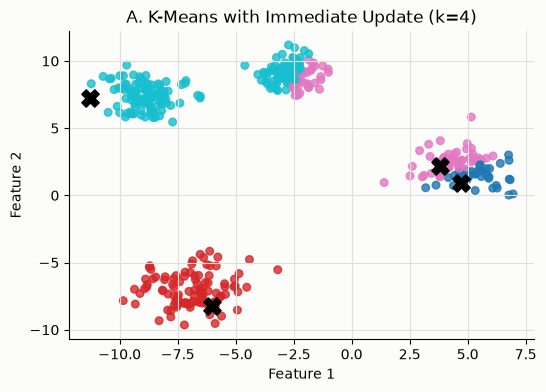

In [4]:
kA = KMeansImmediateUpdate(K=n_clusters, max_iters=100, random_state=42)
yA = kA.fit(X)

print(f'Converged in {kA.n_iters_used} pass(es)')
print(f'Inertia : {kA.inertia:.2f}')
print(f'ARI     : {adjusted_rand_score(y_true, yA):.3f}')
print(f'NMI     : {normalized_mutual_info_score(y_true, yA):.3f}')

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=yA, cmap='tab10', alpha=0.8, s=30)
plt.scatter(kA.centroids[:, 0], kA.centroids[:, 1], c='black', marker='X', s=150, edgecolors='k', linewidths=1.2, zorder=5)
plt.title('A. K-Means with Immediate Update (k=4)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()


In [5]:
def kpp_init(X, K, rng):
    """K-Means++ initialization: sample K centers, each with probability proportional to D(x)^2."""
    n = X.shape[0]
    centers = np.empty((K, X.shape[1]))
    centers[0] = X[rng.integers(n)]
    for j in range(1, K):
        # D(x) = squared distance to the NEAREST already-chosen center
        D = np.min(
            np.stack([np.sum((X - centers[i]) ** 2, axis=1) for i in range(j)], axis=1),
            axis=1)
        if D.sum() == 0:  # degenerate: all points identical
            centers[j] = X[rng.integers(n)]
        else:
            centers[j] = X[rng.choice(n, p=D / D.sum())]
    return centers

class KMeansPlusPlus:
    """K-Means with K-Means++ initialization, batch updates."""
    def __init__(self, K, max_iters=100, tol=1e-8, random_state=42):
        self.K = K
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.n_iters_used = 0

    def fit(self, X):
        self.X = X
        n = X.shape[0]
        rng = np.random.default_rng(self.random_state)

        centers = kpp_init(X, self.K, rng)

        labels = np.zeros(n, dtype=int)
        for it in range(1, self.max_iters + 1):
            # assign step
            D = np.stack([np.sum((X - c) ** 2, axis=1) for c in centers], axis=1)
            new_labels = np.argmin(D, axis=1)
            # update step
            new_centers = np.empty_like(centers)
            for j in range(self.K):
                members = X[new_labels == j]
                new_centers[j] = (members.mean(axis=0)
                                  if len(members) > 0
                                  else X[rng.integers(n)])
            shift = np.max(np.linalg.norm(new_centers - centers, axis=1))
            centers, labels = new_centers, new_labels
            self.n_iters_used = it
            if shift < self.tol:
                break

        self.centroids = centers
        return labels

    @property
    def inertia(self):
        D = np.stack([np.sum((self.X - c) ** 2, axis=1) for c in self.centroids], axis=1)
        m = np.argmin(D, axis=1)
        return float(D[np.arange(self.X.shape[0]), m].sum())

print('KMeansPlusPlus defined')


KMeansPlusPlus defined


K-Means converged after 6 iteration(s).
  iter 1: centroids = [[5.36, 1.36], [-6.88, -7.0], [1.97, 4.78], [-6.52, 8.12]]
  iter 2: centroids = [[4.86, 1.91], [-6.88, -7.0], [1.38, 5.57], [-5.88, 8.19]]
  iter 3: centroids = [[4.74, 1.97], [-6.88, -7.0], [-0.47, 8.46], [-5.93, 8.18]]
  iter 4: centroids = [[4.75, 2.01], [-6.88, -7.0], [-2.36, 9.1], [-7.99, 7.63]]
  iter 5: centroids = [[4.75, 2.01], [-6.88, -7.0], [-2.61, 9.04], [-8.92, 7.38]]
  iter 6: centroids = [[4.75, 2.01], [-6.88, -7.0], [-2.61, 9.04], [-8.92, 7.38]]


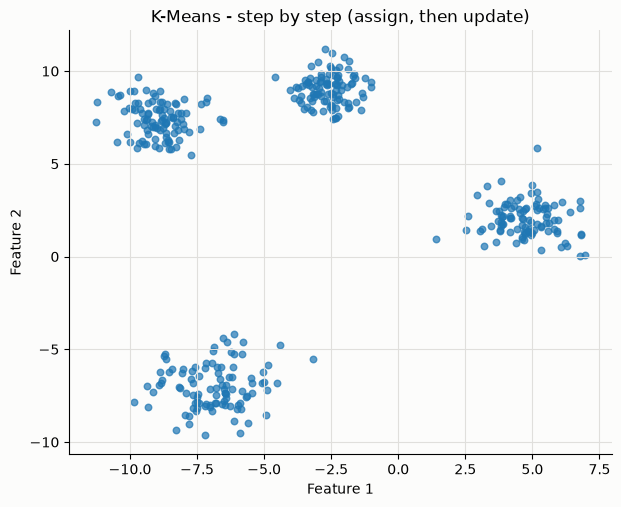

Saved: kmeans_step_by_step.gif


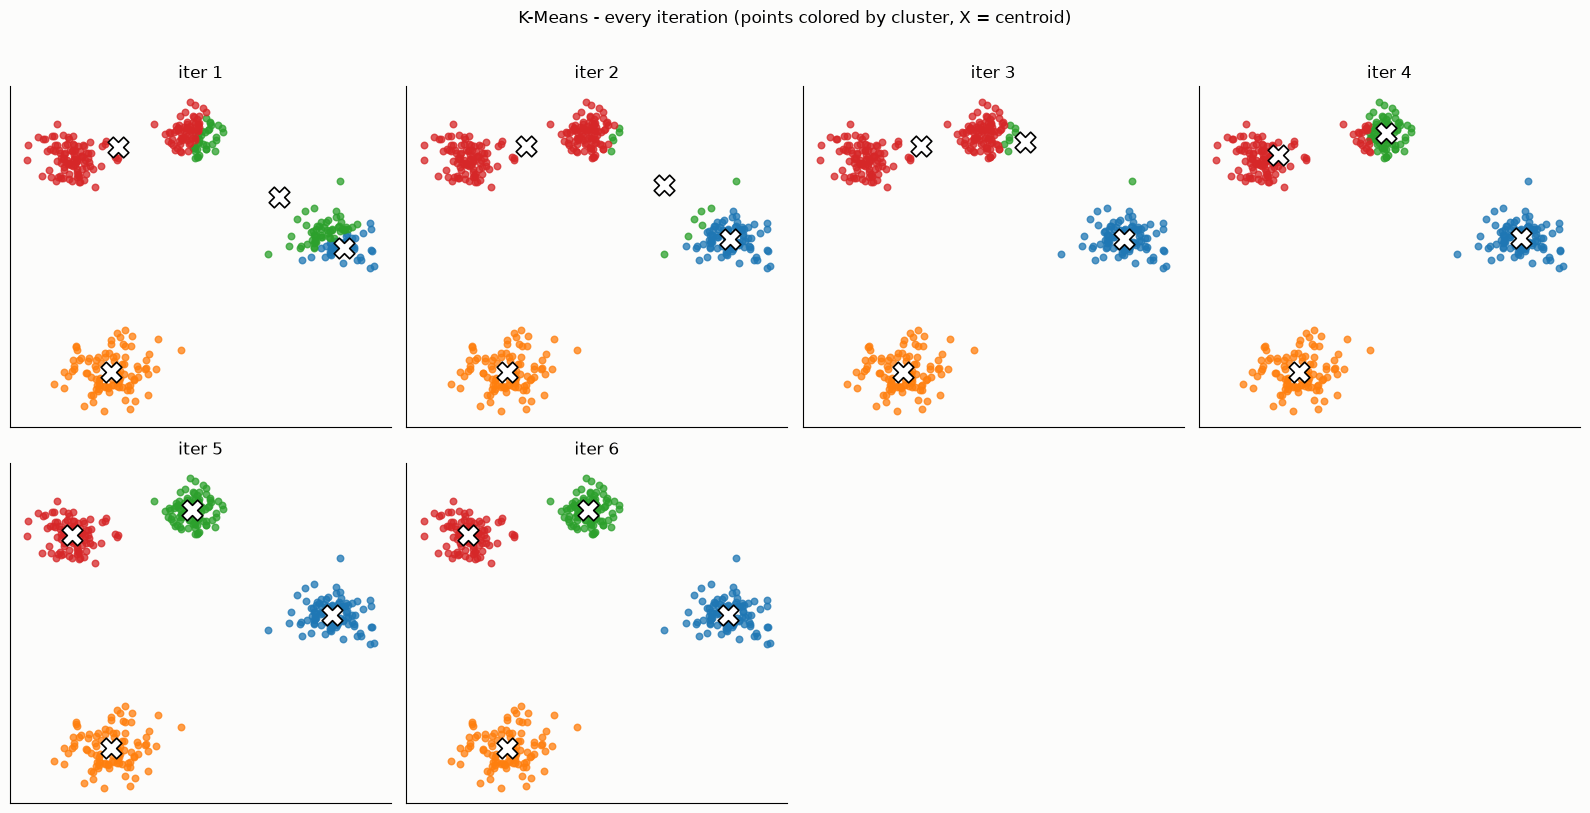

In [6]:
# Step-by-step K-Means: run the from-scratch algorithm, RECORD every iteration,
# then show the assign -> update cycle at each step (animation + a static grid).
import matplotlib.animation as animation

def kmeans_stepwise(X, K, random_state=42, max_iters=20):
    '''K-Means from scratch that records every (labels, centroids) snapshot.'''
    rng = np.random.default_rng(random_state)
    n = X.shape[0]
    idx = rng.choice(n, K, replace=False)
    centers = X[idx].copy()
    snapshots = []
    for it in range(1, max_iters + 1):
        # ASSIGN: each point -> nearest centroid
        D = np.stack([np.sum((X - c) ** 2, axis=1) for c in centers], axis=1)
        labels = np.argmin(D, axis=1)
        # UPDATE: each centroid -> mean of its members
        new_centers = centers.copy()
        for j in range(K):
            members = X[labels == j]
            if len(members) > 0:
                new_centers[j] = members.mean(axis=0)
        snapshots.append(dict(it=it, labels=labels, centroids=new_centers.copy()))
        moved = np.max(np.linalg.norm(new_centers - centers, axis=1))
        centers = new_centers
        if moved < 1e-6:
            break
    return snapshots

snapshots = kmeans_stepwise(X, K=n_clusters, random_state=42)
print(f'K-Means converged after {len(snapshots)} iteration(s).')
for s in snapshots:
    print(f"  iter {s['it']}: centroids = {np.round(s['centroids'], 2).tolist()}")

cmap = plt.get_cmap('tab10')
xs, ys = X[:, 0], X[:, 1]

# 1) Interactive animation (points colored by current cluster, X = centroid)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.set_title('K-Means - step by step (assign, then update)')
ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')
pts = ax.scatter(xs, ys, s=22, alpha=0.7)
cen = ax.scatter([], [], marker='X', s=260, edgecolors='k', linewidths=1.4, color='white', zorder=5)
txt = ax.text(0.02, 0.96, '', transform=ax.transAxes, fontsize=11, va='top')
ax.set_xlim(xs.min() - 1, xs.max() + 1); ax.set_ylim(ys.min() - 1, ys.max() + 1)

def animate(i):
    s = snapshots[i]
    pts.set_array(s['labels'])
    pts.set_color([cmap(int(j) % 10) for j in s['labels']])
    cen.set_offsets(s['centroids'])
    txt.set_text(f"Iteration {i + 1}/{len(snapshots)}: assign points to nearest centroid, then move centroids")
    return pts, cen, txt

anim = animation.FuncAnimation(fig, animate, frames=len(snapshots), interval=900, blit=False, repeat=True)
plt.show()
try:
    anim.save('kmeans_step_by_step.gif', writer='pillow', fps=2)
    print('Saved: kmeans_step_by_step.gif')
except Exception as e:
    print('(GIF not saved - pillow not installed:', e, ')')

# 2) Static grid of every iteration (always visible in the saved report)
n_iter = len(snapshots)
ncols = min(4, n_iter)
nrows = (n_iter + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
for ax in axes.ravel()[n_iter:]:
    ax.axis('off')
for i, s in enumerate(snapshots):
    ax = axes.ravel()[i]
    for j in range(n_clusters):
        m = s['labels'] == j
        ax.scatter(X[m, 0], X[m, 1], s=22, alpha=0.75, color=cmap(j % 10))
    ax.scatter(s['centroids'][:, 0], s['centroids'][:, 1], marker='X', s=220,
               edgecolors='k', linewidths=1.2, color='white', zorder=5)
    ax.set_title(f'iter {i + 1}')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('K-Means - every iteration (points colored by cluster, X = centroid)', y=1.01)
fig.tight_layout()
plt.show()


Converged in 2 iteration(s)
Inertia : 754.64
ARI     : 1.000
NMI     : 1.000


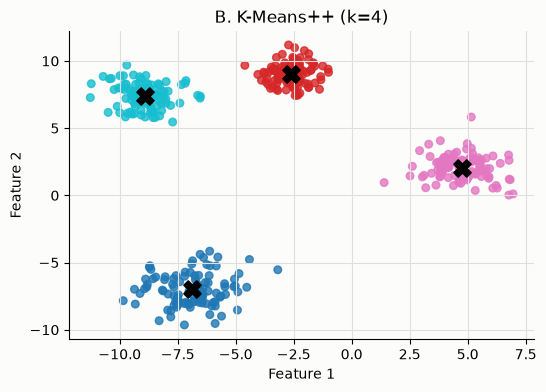

In [7]:
kB = KMeansPlusPlus(K=n_clusters, max_iters=100, random_state=42)
yB = kB.fit(X)

print(f'Converged in {kB.n_iters_used} iteration(s)')
print(f'Inertia : {kB.inertia:.2f}')
print(f'ARI     : {adjusted_rand_score(y_true, yB):.3f}')
print(f'NMI     : {normalized_mutual_info_score(y_true, yB):.3f}')

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=yB, cmap='tab10', alpha=0.8, s=30)
plt.scatter(kB.centroids[:, 0], kB.centroids[:, 1], c='black', marker='X', s=150, edgecolors='k', linewidths=1.2, zorder=5)
plt.title('B. K-Means++ (k=4)')
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.show()


In [8]:
def inertia_of(X, labels, centers):
    D = np.stack([np.sum((X - c) ** 2, axis=1) for c in centers], axis=1)
    return float(D[np.arange(X.shape[0]), labels].sum())

SEEDS = list(range(10))
res_std, res_imm, res_kpp = [], [], []

for s in SEEDS:
    # Standard K-Means (sklearn, n_init=1 so it uses exactly one random init)
    kS = SkKMeans(n_clusters=n_clusters, n_init=1, random_state=s)
    yS = kS.fit_predict(X)
    res_std.append(dict(iters=kS.n_iter_, inertia=kS.inertia_,
                        ari=adjusted_rand_score(y_true, yS),
                        nmi=normalized_mutual_info_score(y_true, yS)))

    # A. Immediate update
    kA = KMeansImmediateUpdate(K=n_clusters, max_iters=100, random_state=s)
    yA = kA.fit(X)
    res_imm.append(dict(iters=kA.n_iters_used, inertia=kA.inertia,
                        ari=adjusted_rand_score(y_true, yA),
                        nmi=normalized_mutual_info_score(y_true, yA)))

    # B. K-Means++
    kB = KMeansPlusPlus(K=n_clusters, max_iters=100, random_state=s)
    yB = kB.fit(X)
    res_kpp.append(dict(iters=kB.n_iters_used, inertia=kB.inertia,
                        ari=adjusted_rand_score(y_true, yB),
                        nmi=normalized_mutual_info_score(y_true, yB)))

def summary(rows):
    return dict(avg_iters=np.mean([r['iters'] for r in rows]),
                avg_inertia=np.mean([r['inertia'] for r in rows]),
                best_inertia=min(r['inertia'] for r in rows),
                avg_ari=np.mean([r['ari'] for r in rows]),
                min_ari=min(r['ari'] for r in rows),
                avg_nmi=np.mean([r['nmi'] for r in rows]))

table = pd.DataFrame({
    'Standard K-Means (random init)': summary(res_std),
    'A. Immediate Update'           : summary(res_imm),
    'B. K-Means++'                  : summary(res_kpp),
}).round(4)
print(table.to_string())


              Standard K-Means (random init)  A. Immediate Update  B. K-Means++
avg_iters                              2.000               1.0000        3.3000
avg_inertia                          754.638           13146.1439     1160.3636
best_inertia                         754.638            1278.4463      754.6380
avg_ari                                1.000               0.6378        0.9263
min_ari                                1.000               0.3447        0.6283
avg_nmi                                1.000               0.7602        0.9603


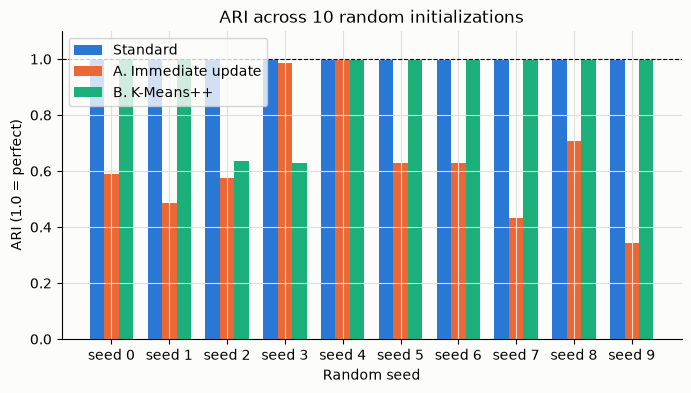

In [9]:
# Per-seed ARI - shows how much each variant depends on its random initialization
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(SEEDS))
width = 0.25
ax.bar(x - width, [r['ari'] for r in res_std], width, label='Standard', color='#2a78d6')
ax.bar(x,         [r['ari'] for r in res_imm], width, label='A. Immediate update', color='#eb6834')
ax.bar(x + width, [r['ari'] for r in res_kpp], width, label='B. K-Means++', color='#1baf7a')
ax.axhline(1.0, color='k', lw=0.8, ls='--')
ax.set_xticks(x); ax.set_xticklabels([f'seed {s}' for s in SEEDS])
ax.set_xlabel('Random seed'); ax.set_ylabel('ARI (1.0 = perfect)')
ax.set_title('ARI across 10 random initializations')
ax.legend(); ax.set_ylim(0, 1.1)
plt.show()


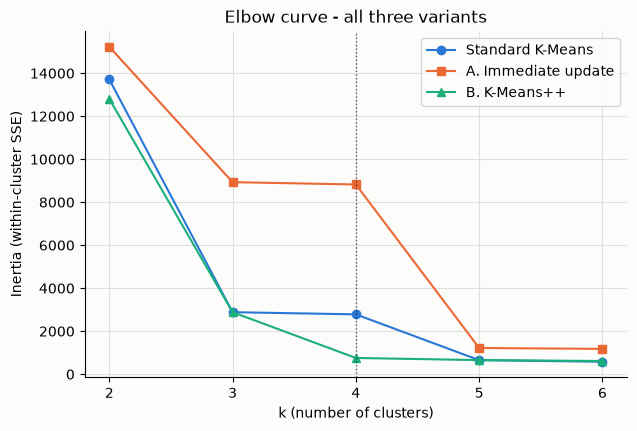

In [10]:
k_range = range(2, 7)
inertia_std, inertia_imm, inertia_kpp = [], [], []
for k in k_range:
    inertia_std.append(SkKMeans(n_clusters=k, n_init=1, random_state=42).fit(X).inertia_)
    mA = KMeansImmediateUpdate(K=k, random_state=42); mA.fit(X); inertia_imm.append(mA.inertia)
    mB = KMeansPlusPlus(K=k, random_state=42);        mB.fit(X); inertia_kpp.append(mB.inertia)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(list(k_range), inertia_std, 'o-', label='Standard K-Means', color='#2a78d6')
ax.plot(list(k_range), inertia_imm, 's-', label='A. Immediate update', color='#eb6834')
ax.plot(list(k_range), inertia_kpp, '^-', label='B. K-Means++', color='#1baf7a')
ax.axvline(4, color='k', ls=':', lw=1, alpha=0.6)
ax.set_xlabel('k (number of clusters)'); ax.set_ylabel('Inertia (within-cluster SSE)')
ax.set_title('Elbow curve - all three variants')
ax.legend(); ax.set_xticks(list(k_range))
plt.show()


variant                           iters    inertia     ARI     NMI
Standard K-Means (n_init=10)          4       78.9   0.730   0.758
A. Immediate update                   1      181.3   0.610   0.705
B. K-Means++                          3       78.9   0.716   0.742


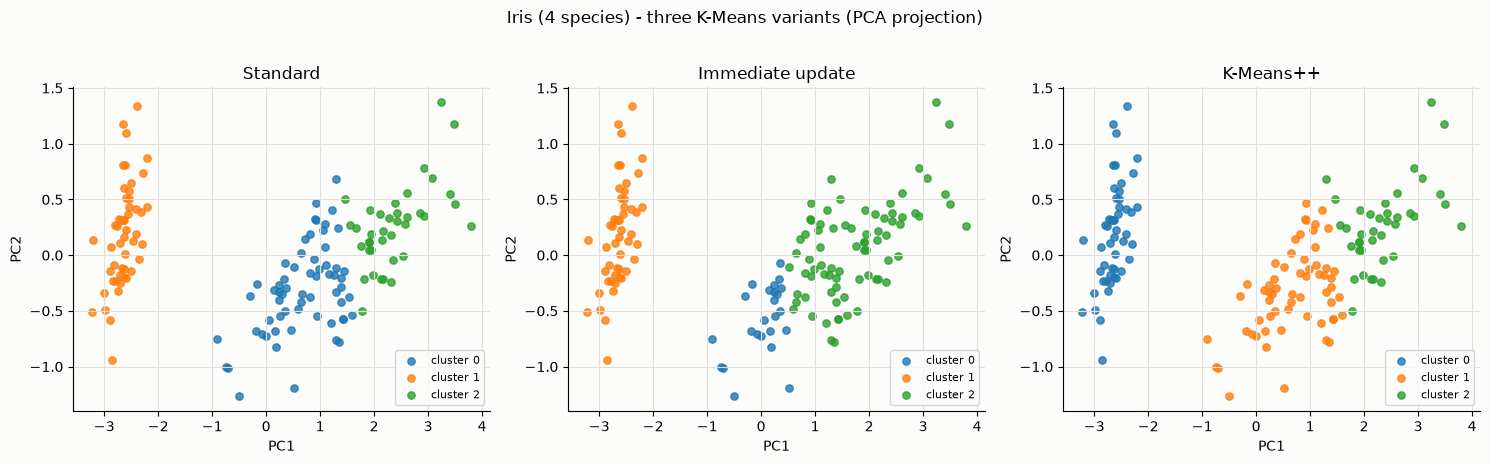

In [11]:
iris = load_iris()
Xi, yi = iris.data, iris.target
ki = len(np.unique(yi))

kS = SkKMeans(n_clusters=ki, n_init=10, random_state=42)
yS = kS.fit_predict(Xi)

kA = KMeansImmediateUpdate(K=ki, max_iters=300, random_state=42)
yA = kA.fit(Xi)

kB = KMeansPlusPlus(K=ki, max_iters=200, random_state=42)
yB = kB.fit(Xi)

rows = [
    ('Standard K-Means (n_init=10)', kS.n_iter_, kS.inertia_, yS),
    ('A. Immediate update',          kA.n_iters_used, kA.inertia, yA),
    ('B. K-Means++',                 kB.n_iters_used, kB.inertia, yB),
]
print(f"{'variant':<32} {'iters':>6} {'inertia':>10} {'ARI':>7} {'NMI':>7}")
for name, iters, iner, y in rows:
    print(f"{name:<32} {iters:>6} {iner:>10.1f} "
          f"{adjusted_rand_score(yi, y):>7.3f} {normalized_mutual_info_score(yi, y):>7.3f}")

from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=0)
Xi2 = pca.fit_transform(Xi)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, y) in zip(axes, [('Standard', yS), ('Immediate update', yA), ('K-Means++', yB)]):
    for j in range(ki):
        mask = y == j
        ax.scatter(Xi2[mask, 0], Xi2[mask, 1], s=28, alpha=0.8, label=f'cluster {j}')
    ax.set_title(name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(fontsize=8)
fig.suptitle('Iris (4 species) - three K-Means variants (PCA projection)', y=1.02)
fig.tight_layout()
plt.show()


# Part 2 - Agglomerative

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_blobs
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as shc

plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e0dfdc',
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Setup complete')


Setup complete


Iris  : X=(150, 4), true clusters=3
Blobs : X=(150, 2), true clusters=3
Iris explained variance: [0.925 0.053] (total 0.98)


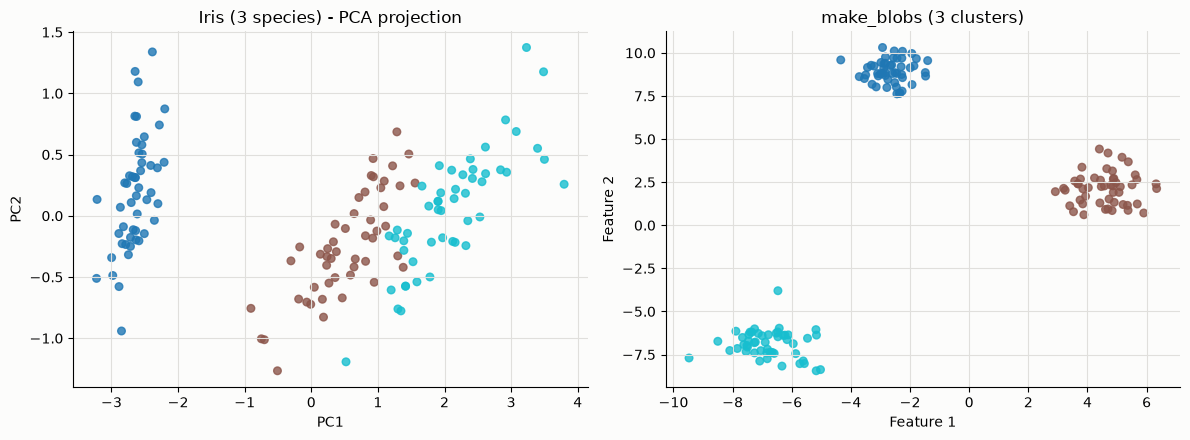

In [13]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

X_blobs, y_blobs = make_blobs(centers=3, n_samples=150, cluster_std=[0.7, 0.9, 0.8], random_state=42)

print(f'Iris  : X={X_iris.shape}, true clusters={len(np.unique(y_iris))}')
print(f'Blobs : X={X_blobs.shape}, true clusters={len(np.unique(y_blobs))}')

# PCA projection for 2-D visualization of the 4-D Iris data
pca = PCA(n_components=2, random_state=0)
X_iris_2d = pca.fit_transform(X_iris)
print(f'Iris explained variance: {pca.explained_variance_ratio_.round(3)} '
      f'(total {pca.explained_variance_ratio_.sum().round(3):.2f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_iris_2d[:, 0], X_iris_2d[:, 1], c=y_iris, cmap='tab10', alpha=0.8, s=30)
axes[0].set_title('Iris (3 species) - PCA projection')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, cmap='tab10', alpha=0.8, s=30)
axes[1].set_title('make_blobs (3 clusters)')
axes[1].set_xlabel('Feature 1'); axes[1].set_ylabel('Feature 2')
plt.tight_layout(); plt.show()


my linkage shape  : (149, 4)
scipy shape       : (149, 4)
ARI (my from-scratch Ward  vs  scipy Ward, cut at k=3): 1.0
(1.0 = my implementation reproduces scipy exactly)


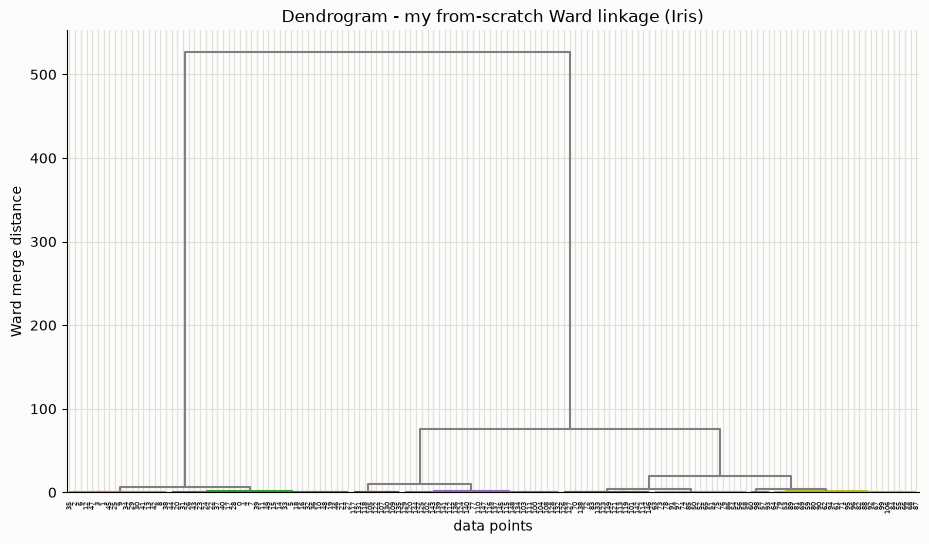

In [14]:
# Agglomerative clustering (Ward linkage) from scratch, using only numpy.

def ward_linkage(X):
    '''Bottom-up agglomerative clustering (Ward's method), from scratch.

    Returns a (n-1, 4) linkage matrix in scipy's layout: [left, right, distance, size].
    left/right are either original point indices (0..n-1) or merge ids (>= n).
    Ward's distance = increase in total within-cluster SSE caused by the merge.
    '''
    n = X.shape[0]
    members = {i: [i] for i in range(n)}   # cluster id -> list of point indices
    alive = list(range(n))
    next_id = n

    def ssq(indices):
        pts = X[indices]
        return float(((pts - pts.mean(axis=0)) ** 2).sum())

    Z = []
    for _ in range(n - 1):
        best_d, best_pair = np.inf, None
        arr = sorted(alive)
        for ai in range(len(arr)):
            a = arr[ai]
            for b in arr[ai + 1:]:
                merged = members[a] + members[b]
                d = ssq(merged) - ssq(members[a]) - ssq(members[b])   # Ward's criterion
                if d < best_d:
                    best_d, best_pair = d, (a, b)
        a, b = best_pair
        members[next_id] = members[a] + members[b]
        Z.append([a, b, best_d, len(members[next_id])])
        alive.remove(a); alive.remove(b); alive.append(next_id)
        next_id += 1
    return np.array(Z)

def cut_linkage(Z, k):
    '''Cut the linkage tree so exactly k clusters remain; return per-point labels 0..k-1.'''
    n = Z.shape[0] + 1
    members = {i: set([i]) for i in range(n)}
    alive = set(range(n))
    next_id = n
    for left, right, _, _ in Z:
        left, right = int(left), int(right)
        if len(alive) == k:            # stop merging once we have exactly k clusters
            break
        members[next_id] = members[left] | members[right]
        alive.discard(left); alive.discard(right); alive.add(next_id)
        next_id += 1
    clusters = sorted(alive)
    label_of = {}
    for new_label, cid in enumerate(clusters):
        for p in members[cid]:
            label_of[p] = new_label
    return np.array([label_of[i] for i in range(n)])

# --- Verify my from-scratch Ward matches scipy's implementation ---
import scipy.cluster.hierarchy as shc
from sklearn.metrics import adjusted_rand_score

Z_mine = ward_linkage(X_iris_2d)
Z_ref = shc.linkage(X_iris_2d, method='ward')
print('my linkage shape  :', Z_mine.shape)
print('scipy shape       :', Z_ref.shape)

labels_mine = cut_linkage(Z_mine, 3)
labels_ref = shc.fcluster(Z_ref, t=3, criterion='maxclust') - 1
print('ARI (my from-scratch Ward  vs  scipy Ward, cut at k=3):',
      round(adjusted_rand_score(labels_mine, labels_ref), 4))
print('(1.0 = my implementation reproduces scipy exactly)')

# Show the merge tree I built, drawn as a proper dendrogram
plt.figure(figsize=(11, 6))
plt.title('Dendrogram - my from-scratch Ward linkage (Iris)')
shc.dendrogram(Z_mine, color_threshold=3, above_threshold_color='gray', leaf_rotation=90)
plt.xlabel('data points'); plt.ylabel('Ward merge distance')
plt.show()


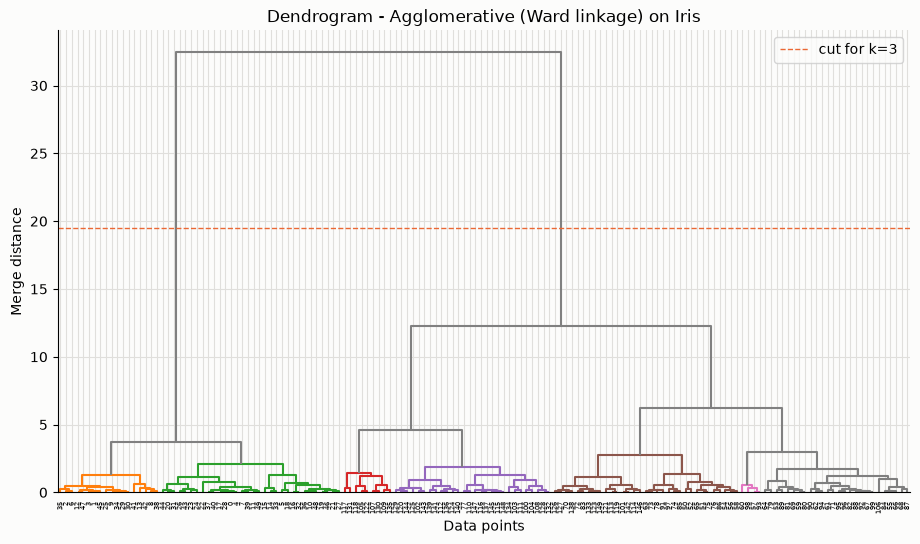

In [15]:
# Dendrogram on the 2-D Iris projection (clear, readable tree)
Z = shc.linkage(X_iris_2d, method='ward')

plt.figure(figsize=(11, 6))
plt.title('Dendrogram - Agglomerative (Ward linkage) on Iris')
shc.dendrogram(Z, color_threshold=3, above_threshold_color='gray', leaf_rotation=90)
plt.xlabel('Data points'); plt.ylabel('Merge distance')
plt.axhline(y=Z[:, 2].max() * 0.6, color='#eb6834', ls='--', lw=1, label='cut for k=3')
plt.legend()
plt.show()


Agglomerative  ARI : 0.731
Agglomerative  NMI : 0.770
Agglomerative  Silhouette (4-D): 0.5543
Agglomerative  Silhouette (2-D): 0.5986


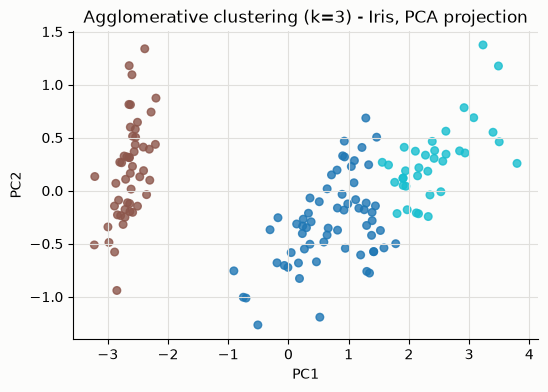

In [16]:
# Agglomerative clustering with k = 3 (matching the true number of species)
agg = AgglomerativeClustering(n_clusters=3)
y_agg = agg.fit_predict(X_iris)

print(f'Agglomerative  ARI : {adjusted_rand_score(y_iris, y_agg):.3f}')
print(f'Agglomerative  NMI : {normalized_mutual_info_score(y_iris, y_agg):.3f}')
print(f'Agglomerative  Silhouette (4-D): {silhouette_score(X_iris, y_agg):.4f}')
print(f'Agglomerative  Silhouette (2-D): {silhouette_score(X_iris_2d, y_agg):.4f}')

plt.figure(figsize=(6, 4))
plt.scatter(X_iris_2d[:, 0], X_iris_2d[:, 1], c=y_agg, cmap='tab10', alpha=0.8, s=30)
plt.title('Agglomerative clustering (k=3) - Iris, PCA projection')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.show()


K-Means  ARI : 0.730
K-Means  NMI : 0.758
K-Means  Inertia: 78.9
K-Means  Silhouette (4-D): 0.5528
K-Means  Silhouette (2-D): 0.5988


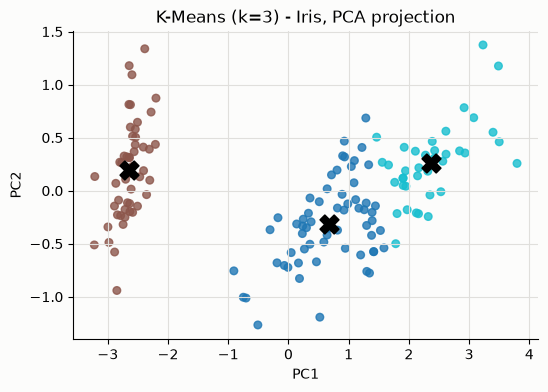

In [17]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
y_km = km.fit_predict(X_iris)

print(f'K-Means  ARI : {adjusted_rand_score(y_iris, y_km):.3f}')
print(f'K-Means  NMI : {normalized_mutual_info_score(y_iris, y_km):.3f}')
print(f'K-Means  Inertia: {km.inertia_:.1f}')
print(f'K-Means  Silhouette (4-D): {silhouette_score(X_iris, y_km):.4f}')
print(f'K-Means  Silhouette (2-D): {silhouette_score(X_iris_2d, y_km):.4f}')

# Project the 4-D cluster centers into the 2-D PCA space for the scatter plot
centers_2d = pca.transform(km.cluster_centers_)

plt.figure(figsize=(6, 4))
plt.scatter(X_iris_2d[:, 0], X_iris_2d[:, 1], c=y_km, cmap='tab10', alpha=0.8, s=30)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='X', s=180, edgecolors='k', linewidths=1.2, zorder=5)
plt.title('K-Means (k=3) - Iris, PCA projection')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.show()


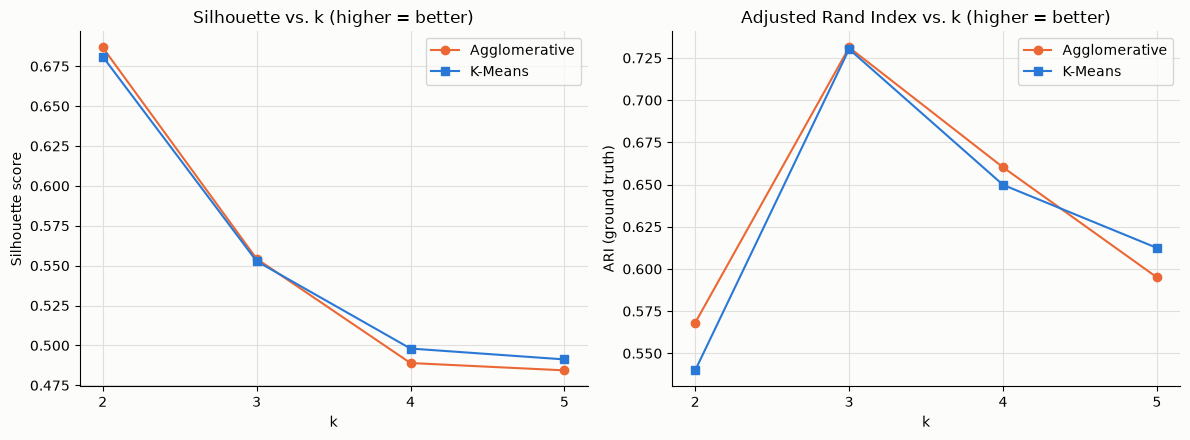

k      Agg. Sil    KM. Sil   Agg. ARI    KM. ARI
2        0.6867     0.6810     0.5681     0.5399
3        0.5543     0.5528     0.7312     0.7302
4        0.4890     0.4981     0.6602     0.6498
5        0.4844     0.4912     0.5950     0.6125


In [18]:
k_range = range(2, 6)
agg_sil, km_sil, agg_ari, km_ari = [], [], [], []

for k in k_range:
    ya = AgglomerativeClustering(n_clusters=k).fit_predict(X_iris)
    yk = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_iris)
    agg_sil.append(silhouette_score(X_iris, ya))
    km_sil.append(silhouette_score(X_iris, yk))
    agg_ari.append(adjusted_rand_score(y_iris, ya))
    km_ari.append(adjusted_rand_score(y_iris, yk))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(k_range), agg_sil, 'o-', label='Agglomerative', color='#eb6834')
axes[0].plot(list(k_range), km_sil, 's-', label='K-Means', color='#2a78d6')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Silhouette score')
axes[0].set_title('Silhouette vs. k (higher = better)')
axes[0].legend(); axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range), agg_ari, 'o-', label='Agglomerative', color='#eb6834')
axes[1].plot(list(k_range), km_ari, 's-', label='K-Means', color='#2a78d6')
axes[1].set_xlabel('k'); axes[1].set_ylabel('ARI (ground truth)')
axes[1].set_title('Adjusted Rand Index vs. k (higher = better)')
axes[1].legend(); axes[1].set_xticks(list(k_range))
plt.tight_layout(); plt.show()

print(f"{'k':<4} {'Agg. Sil':>10} {'KM. Sil':>10} {'Agg. ARI':>10} {'KM. ARI':>10}")
for i, k in enumerate(k_range):
    print(f'{k:<4} {agg_sil[i]:>10.4f} {km_sil[i]:>10.4f} {agg_ari[i]:>10.4f} {km_ari[i]:>10.4f}')


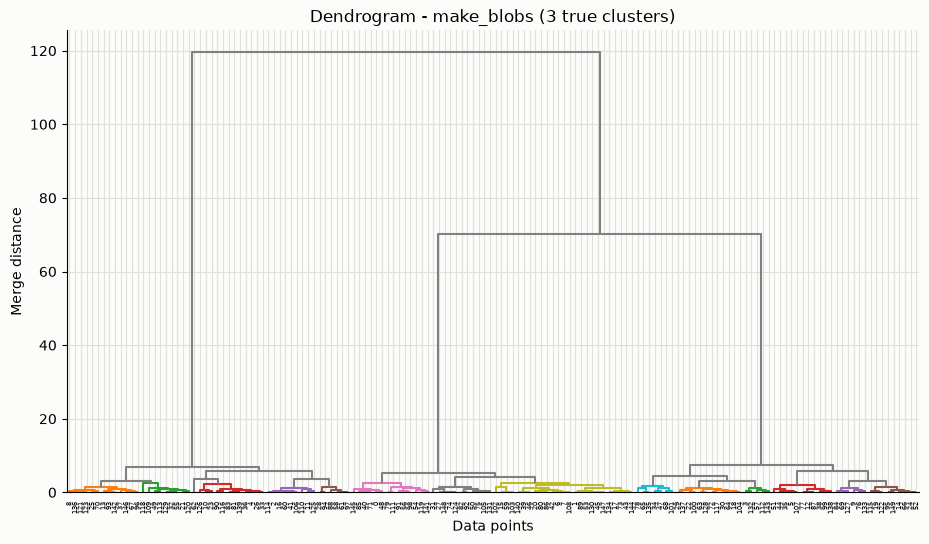

Blobs - Agglomerative  ARI: 1.0  Sil: 0.8755
Blobs - K-Means        ARI: 1.0  Sil: 0.8755


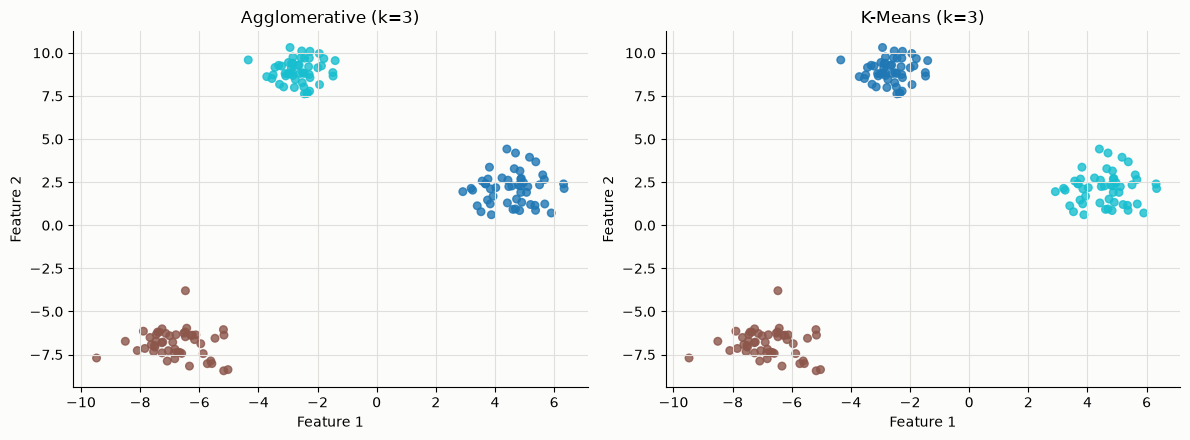

In [19]:
Zb = shc.linkage(X_blobs, method='ward')
plt.figure(figsize=(11, 6))
plt.title('Dendrogram - make_blobs (3 true clusters)')
shc.dendrogram(Zb, color_threshold=3, above_threshold_color='gray', leaf_rotation=90)
plt.xlabel('Data points'); plt.ylabel('Merge distance')
plt.show()

# Confirm: both methods recover 3 clean clusters here
ya = AgglomerativeClustering(n_clusters=3).fit_predict(X_blobs)
yk = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X_blobs)
print('Blobs - Agglomerative  ARI:', round(adjusted_rand_score(y_blobs, ya), 3),
      ' Sil:', round(silhouette_score(X_blobs, ya), 4))
print('Blobs - K-Means        ARI:', round(adjusted_rand_score(y_blobs, yk), 3),
      ' Sil:', round(silhouette_score(X_blobs, yk), 4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=ya, cmap='tab10', alpha=0.8, s=30)
axes[0].set_title('Agglomerative (k=3)')
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=yk, cmap='tab10', alpha=0.8, s=30)
axes[1].set_title('K-Means (k=3)')
for ax in axes: ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2')
plt.tight_layout(); plt.show()


# Part 3 - Direct Comparison

In [20]:
# ------------------------------------------------------------------
# Direct comparison on Iris (3 true species).
# K-Means: default init='k-means++', n_init=10 (best variant).
# Agglomerative: Ward linkage (best for Euclidean data).
# Both scored with the SAME metrics: ARI, NMI, silhouette.
# ------------------------------------------------------------------
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, normalized_mutual_info_score,
                             silhouette_score)

iris = load_iris()
X, y = iris.data, iris.target
k_true = len(np.unique(y))

def score(model, X, y):
    lab = model.fit_predict(X)
    return (adjusted_rand_score(y, lab),
            normalized_mutual_info_score(y, lab),
            silhouette_score(X, lab), lab)

km_lab, ag_lab = None, None
rows = {}
for k in range(2, k_true + 2):  # k = 2..4
    km_ari, km_nmi, km_sil, km_lab_ = score(KMeans(n_clusters=k, n_init=10, random_state=42), X, y)
    ag_ari, ag_nmi, ag_sil, ag_lab_ = score(AgglomerativeClustering(n_clusters=k), X, y)
    rows[k] = dict(km_ari=km_ari, km_nmi=km_nmi, km_sil=km_sil,
                   ag_ari=ag_ari, ag_nmi=ag_nmi, ag_sil=ag_sil)
    if k == k_true:
        km_lab, ag_lab = km_lab_, ag_lab_

print(f"{'k':<4} | {'KM ARI':>7} {'KM NMI':>7} {'KM Sil':>7} | {'Agg ARI':>8} {'Agg NMI':>8} {'Agg Sil':>8}")
print('-' * 74)
for k, r in rows.items():
    print(f"{k:<4} | {r['km_ari']:>7.3f} {r['km_nmi']:>7.3f} {r['km_sil']:>7.4f} | "
          f"{r['ag_ari']:>8.3f} {r['ag_nmi']:>8.3f} {r['ag_sil']:>8.4f}")

r = rows[k_true]
def champ(a, b):
    return 'K-Means' if a > b else ('Agglomerative' if b > a else 'tie')
print()
print(f"At the true k={k_true}:")
print(f"  ARI        winner: {champ(r['km_ari'], r['ag_ari'])}")
print(f"  NMI        winner: {champ(r['km_nmi'], r['ag_nmi'])}")
print(f"  Silhouette winner: {champ(r['km_sil'], r['ag_sil'])}")


k    |  KM ARI  KM NMI  KM Sil |  Agg ARI  Agg NMI  Agg Sil
--------------------------------------------------------------------------
2    |   0.540   0.657  0.6810 |    0.568    0.734   0.6867
3    |   0.730   0.758  0.5528 |    0.731    0.770   0.5543
4    |   0.650   0.722  0.4981 |    0.660    0.710   0.4890

At the true k=3:
  ARI        winner: Agglomerative
  NMI        winner: Agglomerative
  Silhouette winner: Agglomerative


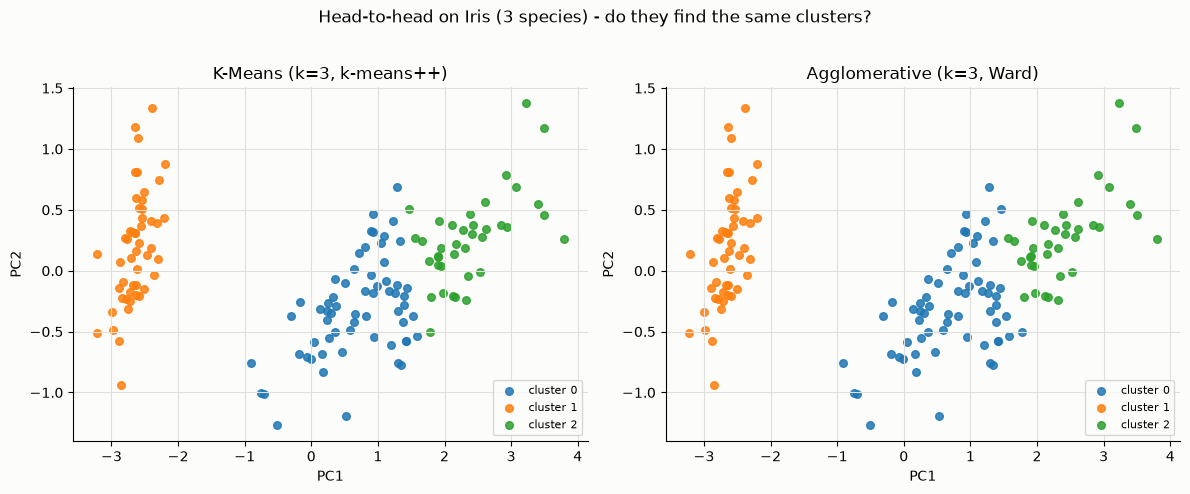

ARI between K-Means and Agglomerative partitions: 0.961
(1.0 = identical clustering; lower = they disagree about where the boundaries go)


In [21]:
# Visual: K-Means vs Agglomerative, both at k=3, on the PCA projection
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=0)
X2 = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, lab, title in [(axes[0], km_lab, 'K-Means (k=3, k-means++)'),
                       (axes[1], ag_lab, 'Agglomerative (k=3, Ward)')]:
    for j in range(k_true):
        mask = lab == j
        ax.scatter(X2[mask, 0], X2[mask, 1], s=30, alpha=0.85, label=f'cluster {j}')
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(fontsize=8)
fig.suptitle('Head-to-head on Iris (3 species) - do they find the same clusters?', y=1.02)
fig.tight_layout()
plt.show()

# How much do the two methods DISAGREE with each other? (ARI between them)
agree = adjusted_rand_score(km_lab, ag_lab)
print(f"ARI between K-Means and Agglomerative partitions: {agree:.3f}")
print('(1.0 = identical clustering; lower = they disagree about where the boundaries go)')


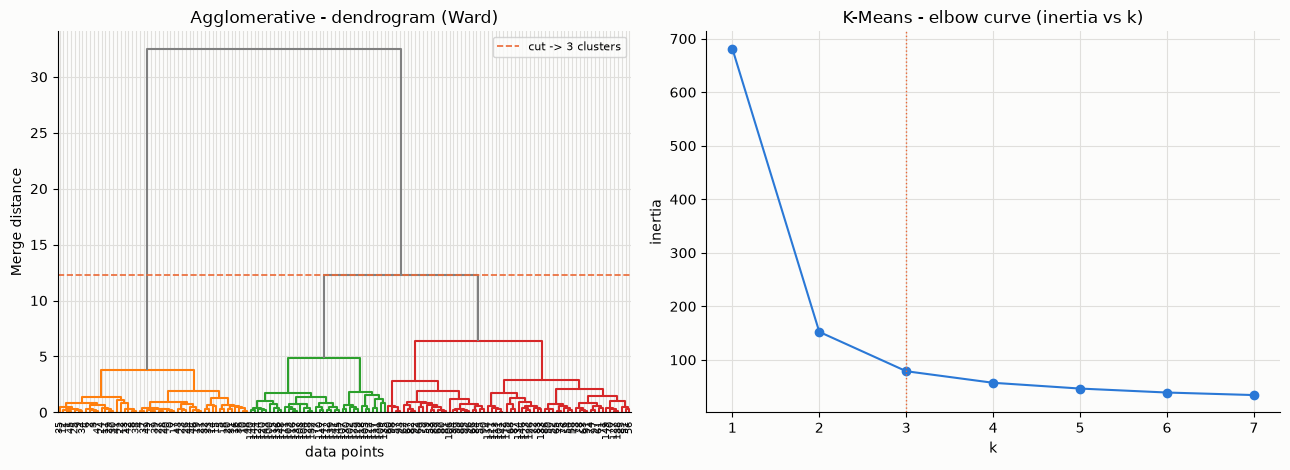

: 

In [ ]:
import scipy.cluster.hierarchy as shc
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Agglomerative: dendrogram, colored by DISTANCE so the cut lines up with the y-axis.
Z = shc.linkage(X, method='ward')
# The merge distance that splits the tree into exactly k_true clusters:
# scipy: the (k-1)th-from-top merge is the one that joins the last two clusters
dist_cut = float(Z[-(k_true - 1), 2])
axes[0].set_title('Agglomerative - dendrogram (Ward)')
shc.dendrogram(
    Z,
    color_threshold=dist_cut,                 # color by merge DISTANCE (matches the y-axis)
    above_threshold_color='gray',
    leaf_rotation=90,
    leaf_font_size=7,
    ax=axes[0],
)
axes[0].axhline(dist_cut, color='#eb6834', ls='--', lw=1.2,
                label=f'cut -> {k_true} clusters')
axes[0].legend(loc='upper right', fontsize=8)
axes[0].set_ylabel('Merge distance')
axes[0].set_xlabel('data points')

# K-Means: elbow
inertias = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 8)]
axes[1].plot(range(1, 8), inertias, 'o-', color='#2a78d6')
axes[1].axvline(k_true, color='#eb6834', ls=':', lw=1)
axes[1].set_title('K-Means - elbow curve (inertia vs k)')
axes[1].set_xlabel('k'); axes[1].set_ylabel('inertia')
axes[1].set_xticks(range(1, 8))
plt.tight_layout(); plt.show()


---
## Verdict - K-Means vs. Agglomerative

| Property | K-Means | Agglomerative (Ward) |
|---|---|---|
| **ARI / NMI / Silhouette on Iris (k=3)** | competitive (0.730 / 0.758 / 0.553) | competitive (0.731 / 0.770 / 0.554) |
| **How `k` is chosen** | elbow curve (heuristic) | **dendrogram gap (direct read)** |
| **Shape assumption** | spherical, equal density | none (distance-based merges) |
| **Deterministic?** | no (init/restarts) | **yes** |
| **Scalability** | **O(n) per iter - scales well** | O(n^2) memory (distance matrix) |
| **Output** | one flat partition | full hierarchy + any cut |
| **Best for** | large `n`, known-ish `k`, speed | small/medium `n`, discovering `k`, shape flexibility |

On well-behaved data the two agree almost perfectly (their ARI with each other is ~0.96). Use **agglomerative** to *discover* `k` and when clusters are irregular; use **K-Means** for large data, roughly-known `k`, and speed.
